<a href="https://colab.research.google.com/github/sushants05-ops/ECGR-4105---Intro-to-Machine-Learning/blob/main/ECGR_4105_Homework_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu

Housing dataset shape: (545, 13)
Cancer dataset shape: (569, 33)

Housing columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Cancer columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Housing numerical features:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Housing categorical features:
['mainroad', 

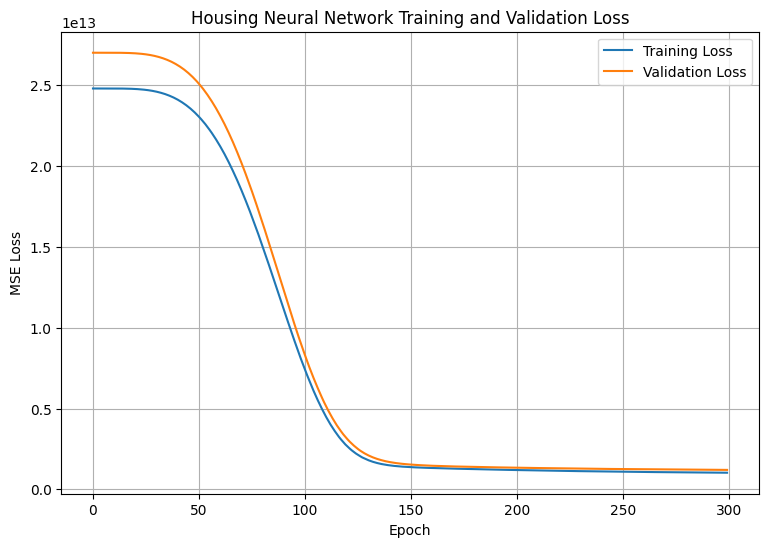


Problem 1a: Housing Neural Network Results
MSE: 1909214150656.0
RMSE: 1381743.1565439359
R2 Score: 0.6222796440124512

Linear Regression Results
MSE: 1754318687330.6682
RMSE: 1324506.9600914402
R2 Score: 0.6529242642153175

SVR Results
MSE: 5561219552192.37
RMSE: 2358223.8129983274
R2 Score: -0.10023588181359688

Housing Model Comparison
                         Model          MSE         RMSE        R2
Fully Connected Neural Network 1.909214e+12 1.381743e+06  0.622280
             Linear Regression 1.754319e+12 1.324507e+06  0.652924
                           SVR 5.561220e+12 2.358224e+06 -0.100236

Best Housing Model based on R2:
Linear Regression

Cancer feature count: 30

Cancer target distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64

Cancer training samples: 455
Cancer testing samples: 114

Neural network cancer training samples: 364
Neural network cancer validation samples: 91

Cancer neural network:
CancerFCNN(
  (network): Sequential(
    (0): Linear(in_fea

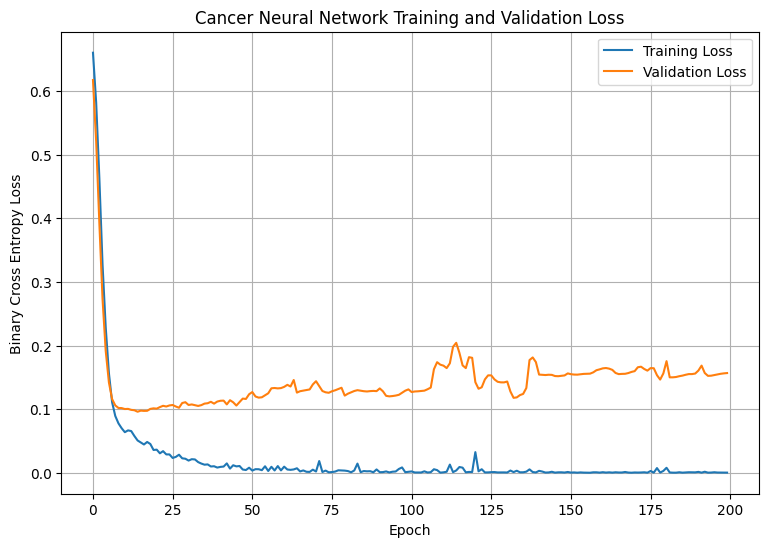

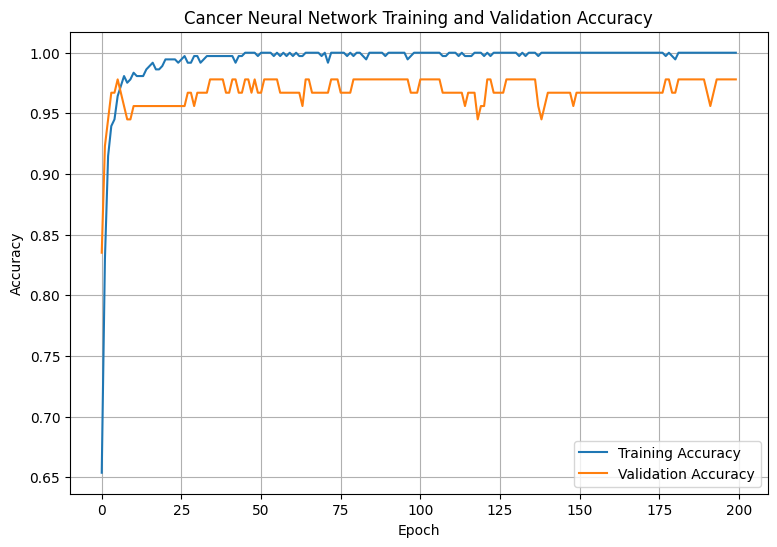


Problem 2a: Cancer Neural Network Results
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219


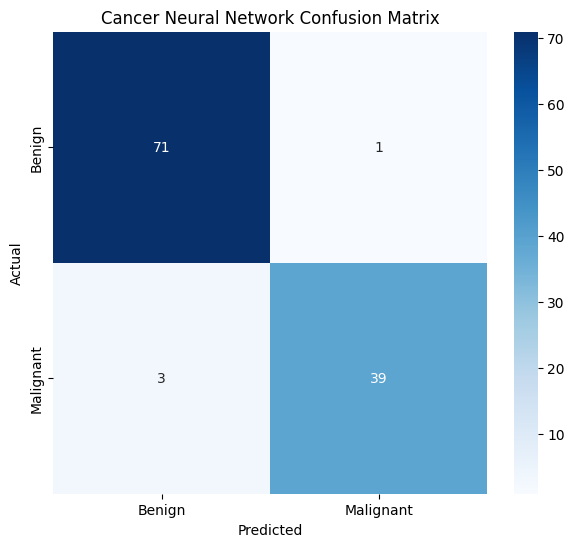


Logistic Regression Results
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219

SVM Results
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629

Cancer Model Comparison
                         Model  Accuracy  Precision   Recall       F1
Fully Connected Neural Network  0.964912      0.975 0.928571 0.951220
           Logistic Regression  0.964912      0.975 0.928571 0.951220
                           SVM  0.973684      1.000 0.928571 0.962963

Best Cancer Model based on F1:
SVM


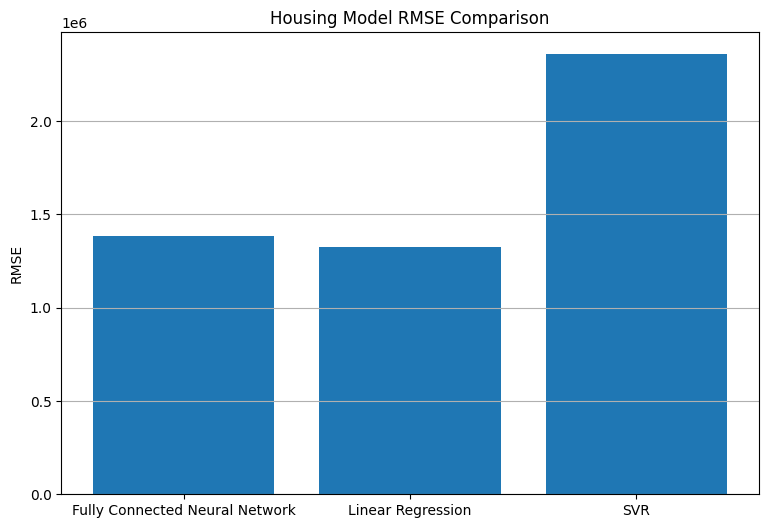

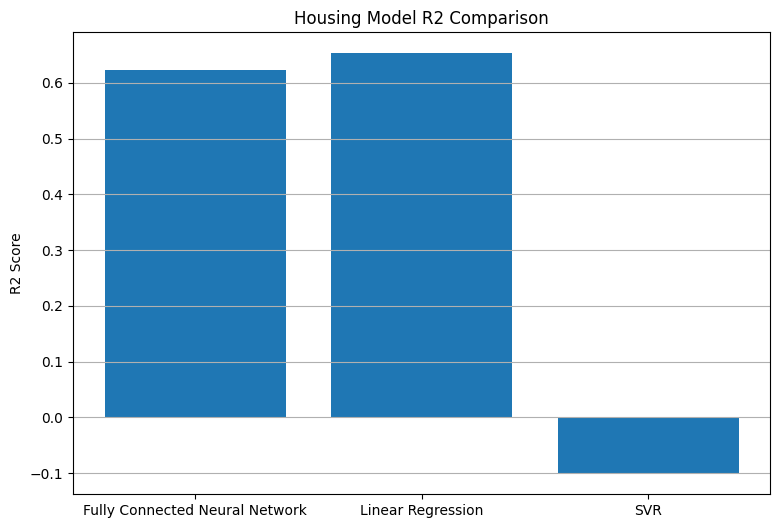

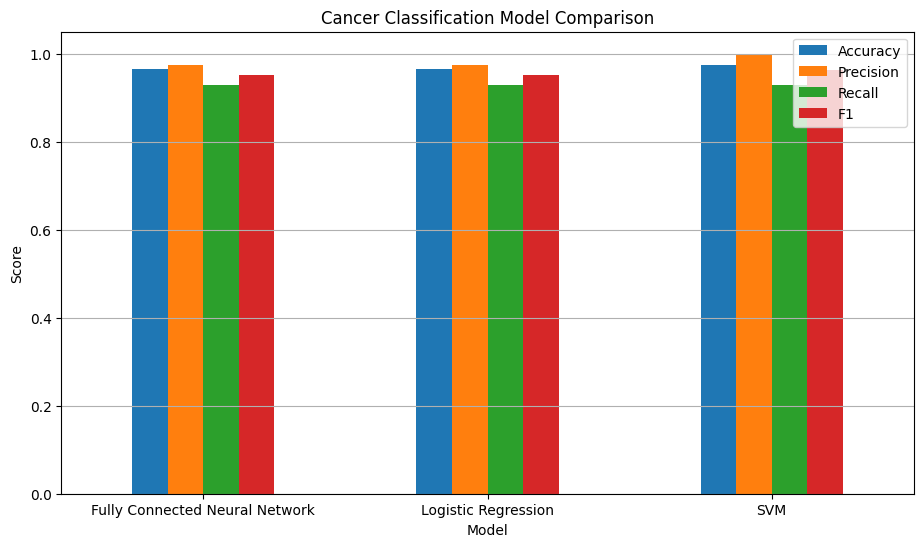


Final Homework 6 Results

Problem 1: Housing Price Prediction
                         Model          MSE         RMSE        R2
Fully Connected Neural Network 1.909214e+12 1.381743e+06  0.622280
             Linear Regression 1.754319e+12 1.324507e+06  0.652924
                           SVR 5.561220e+12 2.358224e+06 -0.100236

Best Housing Model: Linear Regression

Problem 2: Breast Cancer Classification
                         Model  Accuracy  Precision   Recall       F1
Fully Connected Neural Network  0.964912      0.975 0.928571 0.951220
           Logistic Regression  0.964912      0.975 0.928571 0.951220
                           SVM  0.973684      1.000 0.928571 0.962963

Best Cancer Model: SVM

Housing Neural Network Architecture:
Input -> 64 ReLU -> 32 ReLU -> 16 ReLU -> Output

Cancer Neural Network Architecture:
30 Inputs -> 64 ReLU -> Dropout -> 32 ReLU -> Dropout -> 16 ReLU -> Output

Housing Hyperparameters:
Optimizer: Adam
Learning Rate: 0.001
Batch Size: 32
Epochs: 

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


# Set random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# Load datasets
housing_file = "Housing (2).csv"
cancer_file = "Cancer (2).csv"

housing = pd.read_csv(housing_file)
cancer = pd.read_csv(cancer_file)

print("\nHousing dataset shape:", housing.shape)
print("Cancer dataset shape:", cancer.shape)

print("\nHousing columns:")
print(housing.columns.tolist())

print("\nCancer columns:")
print(cancer.columns.tolist())


# Problem 1: Housing Price Prediction

# Separate housing features and target
X_housing = housing.drop(columns=["price"])
y_housing = housing["price"]

# Identify numerical and categorical features
housing_numerical = X_housing.select_dtypes(
    include=[np.number]
).columns.tolist()

housing_categorical = X_housing.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nHousing numerical features:")
print(housing_numerical)

print("\nHousing categorical features:")
print(housing_categorical)


# Create the 80/20 housing split
X_housing_train, X_housing_test, y_housing_train, y_housing_test = train_test_split(
    X_housing,
    y_housing,
    test_size=0.20,
    random_state=SEED
)

print("\nHousing training samples:", len(X_housing_train))
print("Housing testing samples:", len(X_housing_test))


# Create housing preprocessing
housing_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            housing_numerical
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            housing_categorical
        )
    ]
)


# Fit preprocessing using training data only
X_housing_train_processed = housing_preprocessor.fit_transform(
    X_housing_train
)

X_housing_test_processed = housing_preprocessor.transform(
    X_housing_test
)

y_housing_train_np = y_housing_train.to_numpy(
    dtype=np.float32
).reshape(-1, 1)

y_housing_test_np = y_housing_test.to_numpy(
    dtype=np.float32
).reshape(-1, 1)

print("\nProcessed housing training shape:",
      X_housing_train_processed.shape)

print("Processed housing testing shape:",
      X_housing_test_processed.shape)


# Create validation split for neural network
X_house_train_nn, X_house_val_nn, y_house_train_nn, y_house_val_nn = train_test_split(
    X_housing_train_processed,
    y_housing_train_np,
    test_size=0.20,
    random_state=SEED
)

print("\nNeural network housing training samples:",
      len(X_house_train_nn))

print("Neural network housing validation samples:",
      len(X_house_val_nn))


# Convert housing data to tensors
X_house_train_tensor = torch.tensor(
    X_house_train_nn,
    dtype=torch.float32
)

y_house_train_tensor = torch.tensor(
    y_house_train_nn,
    dtype=torch.float32
)

X_house_val_tensor = torch.tensor(
    X_house_val_nn,
    dtype=torch.float32
)

y_house_val_tensor = torch.tensor(
    y_house_val_nn,
    dtype=torch.float32
)

X_house_test_tensor = torch.tensor(
    X_housing_test_processed,
    dtype=torch.float32
)


# Create housing DataLoader
housing_dataset = TensorDataset(
    X_house_train_tensor,
    y_house_train_tensor
)

housing_loader = DataLoader(
    housing_dataset,
    batch_size=32,
    shuffle=True
)


# Define housing neural network
class HousingFCNN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create housing neural network
housing_model = HousingFCNN(
    X_housing_train_processed.shape[1]
).to(device)

print("\nHousing neural network:")
print(housing_model)


# Define housing loss and optimizer
housing_criterion = nn.MSELoss()

housing_optimizer = torch.optim.Adam(
    housing_model.parameters(),
    lr=0.001
)


# Train housing neural network
housing_epochs = 300

housing_train_losses = []
housing_val_losses = []

for epoch in range(housing_epochs):

    housing_model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in housing_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        housing_optimizer.zero_grad()

        predictions = housing_model(X_batch)

        loss = housing_criterion(
            predictions,
            y_batch
        )

        loss.backward()

        housing_optimizer.step()

        running_train_loss += (
            loss.item() * len(X_batch)
        )

    train_loss = (
        running_train_loss /
        len(housing_loader.dataset)
    )

    housing_model.eval()

    with torch.no_grad():

        validation_predictions = housing_model(
            X_house_val_tensor.to(device)
        )

        validation_loss = housing_criterion(
            validation_predictions,
            y_house_val_tensor.to(device)
        ).item()

    housing_train_losses.append(train_loss)
    housing_val_losses.append(validation_loss)

    if (epoch + 1) % 25 == 0:

        print(
            f"Housing Epoch {epoch + 1}/{housing_epochs} "
            f"Train Loss: {train_loss:.4f} "
            f"Validation Loss: {validation_loss:.4f}"
        )


# Plot housing training and validation loss
plt.figure(figsize=(9, 6))

plt.plot(
    housing_train_losses,
    label="Training Loss"
)

plt.plot(
    housing_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Housing Neural Network Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Evaluate housing neural network
housing_model.eval()

with torch.no_grad():

    housing_nn_predictions = housing_model(
        X_house_test_tensor.to(device)
    ).cpu().numpy().flatten()

housing_actual = y_housing_test_np.flatten()

housing_nn_mse = mean_squared_error(
    housing_actual,
    housing_nn_predictions
)

housing_nn_rmse = np.sqrt(
    housing_nn_mse
)

housing_nn_r2 = r2_score(
    housing_actual,
    housing_nn_predictions
)

print("\nProblem 1a: Housing Neural Network Results")
print("MSE:", housing_nn_mse)
print("RMSE:", housing_nn_rmse)
print("R2 Score:", housing_nn_r2)


# Problem 1b: Linear Regression

linear_model = LinearRegression()

linear_model.fit(
    X_housing_train_processed,
    y_housing_train
)

linear_predictions = linear_model.predict(
    X_housing_test_processed
)

linear_mse = mean_squared_error(
    y_housing_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    linear_mse
)

linear_r2 = r2_score(
    y_housing_test,
    linear_predictions
)

print("\nLinear Regression Results")
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)


# Problem 1b: Support Vector Regression

svr_model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

svr_model.fit(
    X_housing_train_processed,
    y_housing_train
)

svr_predictions = svr_model.predict(
    X_housing_test_processed
)

svr_mse = mean_squared_error(
    y_housing_test,
    svr_predictions
)

svr_rmse = np.sqrt(
    svr_mse
)

svr_r2 = r2_score(
    y_housing_test,
    svr_predictions
)

print("\nSVR Results")
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)
print("R2 Score:", svr_r2)


# Create housing comparison table
housing_results = pd.DataFrame({
    "Model": [
        "Fully Connected Neural Network",
        "Linear Regression",
        "SVR"
    ],
    "MSE": [
        housing_nn_mse,
        linear_mse,
        svr_mse
    ],
    "RMSE": [
        housing_nn_rmse,
        linear_rmse,
        svr_rmse
    ],
    "R2": [
        housing_nn_r2,
        linear_r2,
        svr_r2
    ]
})

print("\nHousing Model Comparison")
print(housing_results.to_string(index=False))


# Find best housing model
best_housing_model = housing_results.loc[
    housing_results["R2"].idxmax(),
    "Model"
]

print("\nBest Housing Model based on R2:")
print(best_housing_model)


# Problem 2: Breast Cancer Classification

# Remove non-feature columns
cancer = cancer.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Separate cancer features and target
X_cancer = cancer.drop(
    columns=["diagnosis"]
)

y_cancer = cancer["diagnosis"]


# Convert diagnosis to binary values
y_cancer = y_cancer.map({
    "B": 0,
    "M": 1
})


# Remove rows with missing target values
valid_rows = y_cancer.notna()

X_cancer = X_cancer.loc[valid_rows]
y_cancer = y_cancer.loc[valid_rows]


# Convert cancer features to numeric
X_cancer = X_cancer.apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nCancer feature count:", X_cancer.shape[1])

print("\nCancer target distribution:")
print(y_cancer.value_counts())


# Create the 80/20 stratified cancer split
X_cancer_train, X_cancer_test, y_cancer_train, y_cancer_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.20,
    random_state=SEED,
    stratify=y_cancer
)

print("\nCancer training samples:", len(X_cancer_train))
print("Cancer testing samples:", len(X_cancer_test))


# Fill missing values using training medians
cancer_medians = X_cancer_train.median()

X_cancer_train = X_cancer_train.fillna(
    cancer_medians
)

X_cancer_test = X_cancer_test.fillna(
    cancer_medians
)


# Standardize cancer features
cancer_scaler = StandardScaler()

X_cancer_train_scaled = cancer_scaler.fit_transform(
    X_cancer_train
)

X_cancer_test_scaled = cancer_scaler.transform(
    X_cancer_test
)


# Create validation split for neural network
X_cancer_train_nn, X_cancer_val_nn, y_cancer_train_nn, y_cancer_val_nn = train_test_split(
    X_cancer_train_scaled,
    y_cancer_train.to_numpy(),
    test_size=0.20,
    random_state=SEED,
    stratify=y_cancer_train
)

print("\nNeural network cancer training samples:",
      len(X_cancer_train_nn))

print("Neural network cancer validation samples:",
      len(X_cancer_val_nn))


# Convert cancer data to tensors
X_cancer_train_tensor = torch.tensor(
    X_cancer_train_nn,
    dtype=torch.float32
)

y_cancer_train_tensor = torch.tensor(
    y_cancer_train_nn,
    dtype=torch.float32
).reshape(-1, 1)

X_cancer_val_tensor = torch.tensor(
    X_cancer_val_nn,
    dtype=torch.float32
)

y_cancer_val_tensor = torch.tensor(
    y_cancer_val_nn,
    dtype=torch.float32
).reshape(-1, 1)

X_cancer_test_tensor = torch.tensor(
    X_cancer_test_scaled,
    dtype=torch.float32
)


# Create cancer DataLoader
cancer_dataset = TensorDataset(
    X_cancer_train_tensor,
    y_cancer_train_tensor
)

cancer_loader = DataLoader(
    cancer_dataset,
    batch_size=32,
    shuffle=True
)


# Define cancer neural network
class CancerFCNN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create cancer neural network
cancer_model = CancerFCNN(
    X_cancer_train_scaled.shape[1]
).to(device)

print("\nCancer neural network:")
print(cancer_model)


# Define cancer loss and optimizer
cancer_criterion = nn.BCEWithLogitsLoss()

cancer_optimizer = torch.optim.Adam(
    cancer_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)


# Train cancer neural network
cancer_epochs = 200

cancer_train_losses = []
cancer_val_losses = []

cancer_train_accuracies = []
cancer_val_accuracies = []

for epoch in range(cancer_epochs):

    cancer_model.train()

    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for X_batch, y_batch in cancer_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        cancer_optimizer.zero_grad()

        logits = cancer_model(X_batch)

        loss = cancer_criterion(
            logits,
            y_batch
        )

        loss.backward()

        cancer_optimizer.step()

        running_train_loss += (
            loss.item() * len(X_batch)
        )

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= 0.5
        ).float()

        correct_train += (
            predictions == y_batch
        ).sum().item()

        total_train += len(X_batch)

    train_loss = (
        running_train_loss /
        len(cancer_loader.dataset)
    )

    train_accuracy = (
        correct_train /
        total_train
    )

    cancer_model.eval()

    with torch.no_grad():

        validation_logits = cancer_model(
            X_cancer_val_tensor.to(device)
        )

        validation_loss = cancer_criterion(
            validation_logits,
            y_cancer_val_tensor.to(device)
        ).item()

        validation_probabilities = torch.sigmoid(
            validation_logits
        )

        validation_predictions = (
            validation_probabilities >= 0.5
        ).float()

        validation_accuracy = (
            validation_predictions ==
            y_cancer_val_tensor.to(device)
        ).float().mean().item()

    cancer_train_losses.append(train_loss)
    cancer_val_losses.append(validation_loss)

    cancer_train_accuracies.append(train_accuracy)
    cancer_val_accuracies.append(validation_accuracy)

    if (epoch + 1) % 20 == 0:

        print(
            f"Cancer Epoch {epoch + 1}/{cancer_epochs} "
            f"Train Loss: {train_loss:.4f} "
            f"Validation Loss: {validation_loss:.4f} "
            f"Train Accuracy: {train_accuracy:.4f} "
            f"Validation Accuracy: {validation_accuracy:.4f}"
        )


# Plot cancer training and validation loss
plt.figure(figsize=(9, 6))

plt.plot(
    cancer_train_losses,
    label="Training Loss"
)

plt.plot(
    cancer_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Cancer Neural Network Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Plot cancer training and validation accuracy
plt.figure(figsize=(9, 6))

plt.plot(
    cancer_train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    cancer_val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Cancer Neural Network Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Evaluate cancer neural network
cancer_model.eval()

with torch.no_grad():

    cancer_test_logits = cancer_model(
        X_cancer_test_tensor.to(device)
    )

    cancer_test_probabilities = torch.sigmoid(
        cancer_test_logits
    ).cpu().numpy().flatten()

cancer_nn_predictions = (
    cancer_test_probabilities >= 0.5
).astype(int)

cancer_actual = y_cancer_test.to_numpy()


# Calculate neural network classification metrics
cancer_nn_accuracy = accuracy_score(
    cancer_actual,
    cancer_nn_predictions
)

cancer_nn_precision = precision_score(
    cancer_actual,
    cancer_nn_predictions,
    zero_division=0
)

cancer_nn_recall = recall_score(
    cancer_actual,
    cancer_nn_predictions,
    zero_division=0
)

cancer_nn_f1 = f1_score(
    cancer_actual,
    cancer_nn_predictions,
    zero_division=0
)

print("\nProblem 2a: Cancer Neural Network Results")
print("Accuracy:", cancer_nn_accuracy)
print("Precision:", cancer_nn_precision)
print("Recall:", cancer_nn_recall)
print("F1 Score:", cancer_nn_f1)


# Plot neural network confusion matrix
cancer_nn_cm = confusion_matrix(
    cancer_actual,
    cancer_nn_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cancer_nn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Cancer Neural Network Confusion Matrix")
plt.show()


# Problem 2b: Logistic Regression

logistic_model = LogisticRegression(
    max_iter=5000,
    random_state=SEED
)

logistic_model.fit(
    X_cancer_train_scaled,
    y_cancer_train
)

logistic_predictions = logistic_model.predict(
    X_cancer_test_scaled
)

logistic_accuracy = accuracy_score(
    cancer_actual,
    logistic_predictions
)

logistic_precision = precision_score(
    cancer_actual,
    logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    cancer_actual,
    logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    cancer_actual,
    logistic_predictions,
    zero_division=0
)

print("\nLogistic Regression Results")
print("Accuracy:", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall:", logistic_recall)
print("F1 Score:", logistic_f1)


# Problem 2b: Support Vector Machine

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svm_model.fit(
    X_cancer_train_scaled,
    y_cancer_train
)

svm_predictions = svm_model.predict(
    X_cancer_test_scaled
)

svm_accuracy = accuracy_score(
    cancer_actual,
    svm_predictions
)

svm_precision = precision_score(
    cancer_actual,
    svm_predictions,
    zero_division=0
)

svm_recall = recall_score(
    cancer_actual,
    svm_predictions,
    zero_division=0
)

svm_f1 = f1_score(
    cancer_actual,
    svm_predictions,
    zero_division=0
)

print("\nSVM Results")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)


# Create cancer comparison table
cancer_results = pd.DataFrame({
    "Model": [
        "Fully Connected Neural Network",
        "Logistic Regression",
        "SVM"
    ],
    "Accuracy": [
        cancer_nn_accuracy,
        logistic_accuracy,
        svm_accuracy
    ],
    "Precision": [
        cancer_nn_precision,
        logistic_precision,
        svm_precision
    ],
    "Recall": [
        cancer_nn_recall,
        logistic_recall,
        svm_recall
    ],
    "F1": [
        cancer_nn_f1,
        logistic_f1,
        svm_f1
    ]
})

print("\nCancer Model Comparison")
print(cancer_results.to_string(index=False))


# Find best cancer model
best_cancer_model = cancer_results.loc[
    cancer_results["F1"].idxmax(),
    "Model"
]

print("\nBest Cancer Model based on F1:")
print(best_cancer_model)


# Plot housing RMSE comparison
plt.figure(figsize=(9, 6))

plt.bar(
    housing_results["Model"],
    housing_results["RMSE"]
)

plt.ylabel("RMSE")
plt.title("Housing Model RMSE Comparison")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()


# Plot housing R2 comparison
plt.figure(figsize=(9, 6))

plt.bar(
    housing_results["Model"],
    housing_results["R2"]
)

plt.ylabel("R2 Score")
plt.title("Housing Model R2 Comparison")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()


# Plot cancer model comparison
cancer_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel("Score")
plt.title("Cancer Classification Model Comparison")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.grid(axis="y")
plt.legend()

plt.show()


# Print final results
print("\nFinal Homework 6 Results")

print("\nProblem 1: Housing Price Prediction")
print(housing_results.to_string(index=False))

print("\nBest Housing Model:", best_housing_model)

print("\nProblem 2: Breast Cancer Classification")
print(cancer_results.to_string(index=False))

print("\nBest Cancer Model:", best_cancer_model)

print("\nHousing Neural Network Architecture:")
print("Input -> 64 ReLU -> 32 ReLU -> 16 ReLU -> Output")

print("\nCancer Neural Network Architecture:")
print("30 Inputs -> 64 ReLU -> Dropout -> 32 ReLU -> Dropout -> 16 ReLU -> Output")

print("\nHousing Hyperparameters:")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Batch Size: 32")
print("Epochs: 300")

print("\nCancer Hyperparameters:")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Batch Size: 32")
print("Epochs: 200")
print("Dropout: 0.20")
print("Weight Decay: 0.0001")

print("\nAll models use an 80/20 train/test split.")
print("Preprocessing is fitted using training data only.")
print("Random seed:", SEED)